# In-memory vLLM + DSPy grouping demo

Every other script in this repo (`fetch_groups.py`, etc.) talks to the model through
`dspy.LM('openai/'+model, api_base=..., api_key=...)`, which requires a separate `vllm serve <model>`
process already running and reachable over HTTP.

This notebook instead **loads `Qwen/Qwen2.5-VL-7B-Instruct` directly into this process's memory**
using vLLM's offline `LLM` engine (no `vllm serve`, no HTTP server, no separate process), and then
runs the *exact same* DSPy grouping signature/module the rest of the pipeline uses
(`mode='vlm_image'`, `prompt_method='p1'` -> `vlm_IdentifyGroupsImage` via `get_dspy_cot`), on one
real frame + its detections.

**Requirements:**
- Run this notebook with the `py10-dspy` conda kernel (has `dspy` 3.1.3 and `vllm` 0.19.0 installed).
- A GPU with enough free VRAM to load a 7B VL model (loading takes a minute or two and downloads
  weights on first run).
- Working directory must be `claude_code/` (so `utils.py`/`prompts.py` import normally, matching the
  rest of the repo's convention).

In [1]:
import os
import json
import uuid
import datetime

import dspy
from vllm import LLM, SamplingParams

from utils import get_dspy_cot, get_frame_bboxes, inference_wrapper, save_frame

/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


## Custom in-process DSPy LM backed by a local `vllm.LLM` engine

This mirrors the pattern already used in `gemini_dspy.py`'s `GeminiVertexLM(dspy.LM)`: subclass
`dspy.LM` and override `__call__` directly instead of letting DSPy route the call through
`litellm.completion` (which has no way to hand it an in-memory model object). We still manually
record a history entry via `self.update_history(...)` so `lm.history[-1]` keeps working -- it's
read by `inference_wrapper` in `utils.py`.

By the time DSPy calls `__call__`, its chat adapter has already turned any `dspy.Image` input field
into a standard OpenAI-style `image_url` content block (base64 data URI) inside `messages`. vLLM's
offline `LLM.chat(...)` accepts that same message shape directly, so we pass `messages` straight
through unmodified.

In [2]:
class VLLMOfflineLM(dspy.LM):
    """DSPy-compatible LM wrapper around an in-process (offline) vLLM engine."""

    def __init__(self, model, max_tokens=4096, temperature=0.6, **engine_kwargs):
        # Pass a litellm-compatible name to the base class so it doesn't error.
        # We override __call__ so litellm is never actually invoked.
        super().__init__(model=f"openai/{model}", temperature=temperature, max_tokens=max_tokens)

        self.model_name = model
        self.max_tokens = max_tokens
        self.temperature = temperature
        self.engine = LLM(model=model, trust_remote_code=True, **engine_kwargs)

    def __call__(self, prompt=None, messages=None, **kwargs):
        if messages is None:
            messages = [{"role": "user", "content": prompt}]

        sampling_params = SamplingParams(temperature=self.temperature, max_tokens=self.max_tokens)
        [result] = self.engine.chat(messages, sampling_params=sampling_params, use_tqdm=False)
        text = result.outputs[0].text
        outputs = [text]

        entry = {
            "prompt": prompt,
            "messages": messages,
            "kwargs": kwargs,
            "response": text,
            "outputs": outputs,
            "usage": {
                "prompt_tokens": len(result.prompt_token_ids),
                "completion_tokens": len(result.outputs[0].token_ids),
                "total_tokens": len(result.prompt_token_ids) + len(result.outputs[0].token_ids),
            },
            "cost": None,
            "timestamp": datetime.datetime.now().isoformat(),
            "uuid": str(uuid.uuid4()),
            "model": self.model,
            "response_model": self.model_name,
            "model_type": "chat",
        }
        self.update_history(entry)

        return outputs

## Load one scenario + frame

Uses a real scenario JSON + matching frame image from the SEKAI gold dataset (sibling directory to
this repo, per the `../../<dataset>` convention documented in `CLAUDE.md`).

In [3]:
scenario_path = '../../gold_SEKAI_900_3/jsons_step5/clip_0004.json'
frame_id = 1
frame_path = '../../gold_SEKAI_900_3/videos_frames/clip_0004/00001.jpeg'

with open(scenario_path, 'r') as f:
    data = json.load(f)

print(data['dataset'], '-', len(data['frames']), 'frames')

sekai - 50 frames


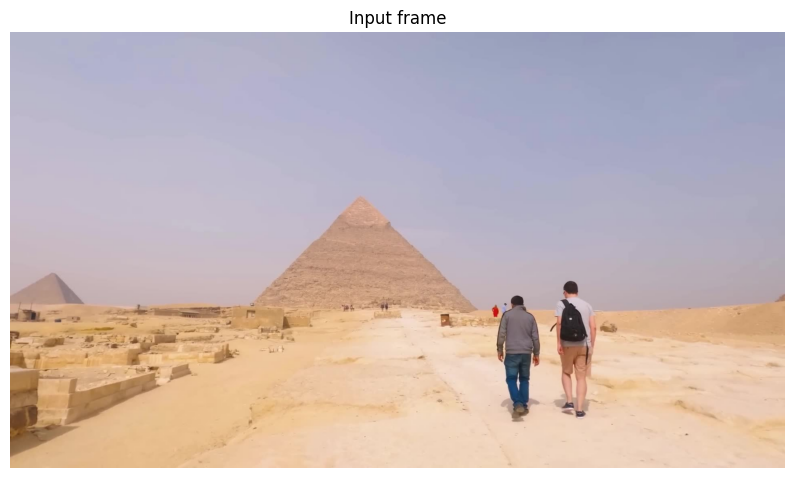

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(10, 6))
plt.imshow(Image.open(frame_path))
plt.axis('off')
plt.title('Input frame')
plt.show()

## Load Qwen2.5-VL-7B-Instruct into memory and configure DSPy

This loads the model weights onto the GPU -- no server, no `api_base`. Takes a minute or two.

In [5]:
lm = VLLMOfflineLM(
    model="Qwen/Qwen3-VL-8B-Instruct",
    max_tokens=8096,
    temperature=0.6,
    limit_mm_per_prompt={"image": 1},
)
dspy.configure(lm=lm, adapter = dspy.JSONAdapter())

INFO 07-03 23:54:59 [utils.py:233] non-default args: {'trust_remote_code': True, 'disable_log_stats': True, 'limit_mm_per_prompt': {'image': 1}, 'model': 'Qwen/Qwen3-VL-8B-Instruct'}
INFO 07-03 23:54:59 [model.py:549] Resolved architecture: Qwen3VLForConditionalGeneration
INFO 07-03 23:54:59 [model.py:1678] Using max model len 262144
INFO 07-03 23:54:59 [scheduler.py:238] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 07-03 23:54:59 [vllm.py:790] Asynchronous scheduling is enabled.
(EngineCore pid=2888106) INFO 07-03 23:55:05 [core.py:105] Initializing a V1 LLM engine (v0.19.0) with config: model='Qwen/Qwen3-VL-8B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen3-VL-8B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=True, dtype=torch.bfloat16, max_seq_len=262144, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parall

(EngineCore pid=2888106) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
(EngineCore pid=2888106) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.
Loading safetensors checkpoint shards:   0% Completed | 0/4 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  25% Completed | 1/4 [00:00<00:02,  1.10it/s]
Loading safetensors checkpoint shards:  50% Completed | 2/4 [00:02<00:02,  1.03s/it]
Loading safetensors checkpoint shards:  75% Completed | 3/4 [00:03<00:01,  1.02s/it]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:03<00:00,  1.21it/s]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:03<00:00,  1.12it/s]
(EngineCore pid=2888106) 


(EngineCore pid=2888106) INFO 07-03 23:55:13 [default_loader.py:384] Loading weights took 3.58 seconds
(EngineCore pid=2888106) INFO 07-03 23:55:14 [gpu_model_runner.py:4820] Model loading took 16.78 GiB memory and 4.753559 seconds
(EngineCore pid=2888106) INFO 07-03 23:55:14 [gpu_model_runner.py:5753] Encoder cache will be initialized with a budget of 16384 tokens, and profiled with 1 image items of the maximum feature size.
(EngineCore pid=2888106) INFO 07-03 23:55:26 [backends.py:1051] Using cache directory: /home/nvidia/.cache/vllm/torch_compile_cache/30420a589b/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=2888106) INFO 07-03 23:55:26 [backends.py:1111] Dynamo bytecode transform time: 7.84 s
(EngineCore pid=2888106) INFO 07-03 23:55:35 [backends.py:372] Cache the graph of compile range (1, 8192) for later use
(EngineCore pid=2888106) INFO 07-03 23:55:46 [backends.py:390] Compiling a graph for compile range (1, 8192) takes 18.84 s
(EngineCore pid=2888106) INFO 07-03 23

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|█| 51/51 [00:0
Capturing CUDA graphs (decode, FULL): 100%|█| 35/35 [00:03<00:00,  9.20it/s]


(EngineCore pid=2888106) INFO 07-03 23:55:59 [gpu_model_runner.py:6046] Graph capturing finished in 7 secs, took 0.54 GiB
(EngineCore pid=2888106) INFO 07-03 23:55:59 [gpu_worker.py:597] CUDA graph pool memory: 0.54 GiB (actual), 0.52 GiB (estimated), difference: 0.02 GiB (4.3%).
(EngineCore pid=2888106) INFO 07-03 23:55:59 [core.py:283] init engine (profile, create kv cache, warmup model) took 45.58 seconds


In [6]:
print(type(lm))
print(lm)

<class '__main__.VLLMOfflineLM'>


## Run the same DSPy grouping call as `fetch_groups.py`

`get_dspy_cot`, `get_frame_bboxes`, and `inference_wrapper` are the exact same helper functions the
CLI pipeline uses -- nothing is reimplemented here.

In [7]:
mode = 'vlm_image'
prompt_method = 'p1'
depth_method = 'detany_3D'

dspy_cot, use_direction = get_dspy_cot(mode, prompt_method)
frame_input_data, personid2bbox = get_frame_bboxes(data, use_direction, depth_method, frame_id, prompt_method)

print(f'{len(frame_input_data)} people detected in frame {frame_id}')
frame_input_data[:3]

7 people detected in frame 1


[{'person_id': 1, 'x': -1.6144, 'y': 3.4569, 'z': 45.1992},
 {'person_id': 2, 'x': -3.5211, 'y': 3.268, 'z': 42.3017},
 {'person_id': 3, 'x': 1.7581, 'y': 0.8437, 'z': 6.2711}]

In [10]:
output = inference_wrapper(
    lm, dspy_cot, frame_input_data,
    mode=mode, image_path=frame_path, prompt=prompt_method,
)

print('error:', output['error'])
print('groups:', output['groups'])
print(lm.inspect_history(1))

error: None
groups: [[3, 6], [1, 2, 4, 5, 7]]




[2026-07-03T23:57:20.063777]

System message:

Your input fields are:
1. `image` (Image): Image with people to group
2. `detections` (list[dict]): List of people, where each dictionary has keys: 'person_id', 'x', 'y', 'z'.
Your output fields are:
1. `reasoning` (str): 
2. `groups` (list[list[int]]): A list of groups, where each group is a list of person_ids that are close together. All ids should appear at least once.
All interactions will be structured in the following way, with the appropriate values filled in.

Inputs will have the following structure:

[[ ## image ## ]]
{image}

[[ ## detections ## ]]
{detections}

Outputs will be a JSON object with the following fields.

{
  "reasoning": "{reasoning}",
  "groups": "{groups}        # note: the value you produce must adhere to the JSON schema: {\"type\": \"array\", \"items\": {\"type\": \"array\", \"items\": {\"type\": \"integer\"}}}"
}
In adhering to this structure, your objective i

## Visualize the predicted groups

Reuses `save_frame` (the same function `fetch_groups.py` calls) to draw one color per predicted
group on the frame and save it, then displays the result inline.

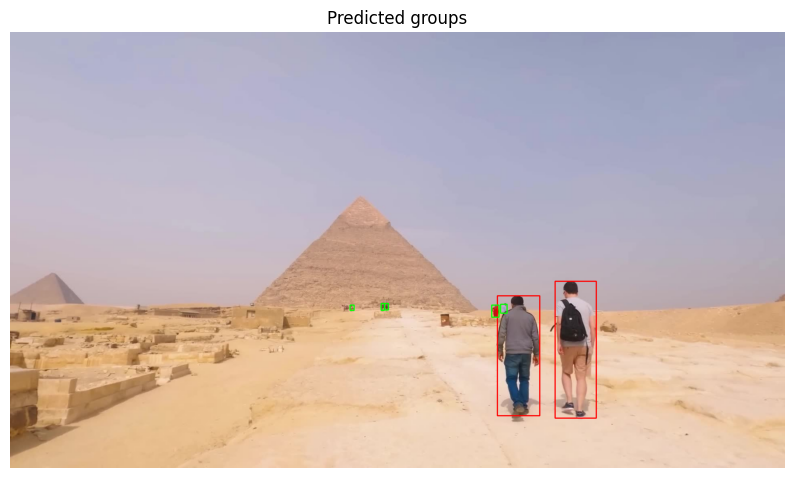

In [11]:
if output['error'] is None:
    output['frame_id'] = frame_id
    output['id_tobbox'] = personid2bbox

    res_path = 'demo_predictions'
    save_filename = 'clip_0001'
    model_name = 'Qwen/Qwen2.5-VL-7B-Instruct'

    #print(output)
    
    save_frame(
        output, personid2bbox, res_path, save_filename, frame_path,
        save_image=True, model=model_name, mode=mode,
        depth_method=depth_method, prompt_method=prompt_method, frame_id=frame_id,
    )

    result_path = os.path.join(
        res_path, model_name.split('/')[1], mode, depth_method,
        prompt_method, str(frame_id), save_filename, 'result.png',
    )

    
    plt.figure(figsize=(10, 6))
    plt.imshow(Image.open(result_path))
    plt.axis('off')
    plt.title('Predicted groups')
    plt.show()
else:
    print('Skipping visualization -- inference errored:', output['error'])

---

**Note:** `vllm.LLM` here is the synchronous/batch *offline* engine, so this pattern serves one
prompt at a time in-process -- great for a quick single-image demo like this, but not a replacement
for the concurrent/parallel batch workloads the rest of the repo runs against a `vllm serve` HTTP
server (see `run_batch_groups.bash`, `scripts/batch_fetch_groups_methods_single.bash`, etc.).